# Open systems: an explicit amplitude-damping dilation

The model is a single qubit with $H=0$, $L=\sqrt{\gamma}|0\rangle\langle1|$, rate $\gamma=0.8$ in inverse time units and $\hbar=1$. Its finite-time channel has $p(t)=1-e^{-\gamma t}$. The actual quantum implementation uses a zero-input environment, controlled RY and CX. The Kraus formula below is an independent small classical check, not a circuit gate.

The original implementation is MIT code using Qiskit 2.6.2 (Apache-2.0) and NumPy. The chapter credits Stinespring's dilation theorem, the GKSL source and exact upstream package source. General interacting Lindblad simulation remains planned.

In [1]:
from pathlib import Path
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "src/openquantum/simulation/open_systems.py").exists() and (root.parent / "src/openquantum/simulation/open_systems.py").exists():
    root = root.parent
if (root / "src/openquantum/simulation/open_systems.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum.simulation import open_systems as osq
else:
    # Save downloaded open_systems.py beside this notebook.
    sys.path.insert(0, str(root))
    import open_systems as osq

rate = 0.8
input_labels = osq.INPUT_LABELS
validation_times = (0, 0.25, 0.5, 1, 2, 50)
print(f"Finite-time damping probability at t=1: {osq.damping_probability(rate, 1):.12f}")

Finite-time damping probability at t=1: 0.550671035883


## Circuit and environment protocol

Wire q0 is the system, q1 the environment. Named inputs are prepared with X/H/S gates. Initial resets are explicit in measured trials. The circuit applies CRY with angle $2\operatorname{atan2}(\sqrt p,e^{-\gamma t/2})$ controlled by the system, then a CX from environment to system. Every environment outcome is ignored, not postselected. The system is measured in the requested basis; a retained state output instead describes the system before final readout.

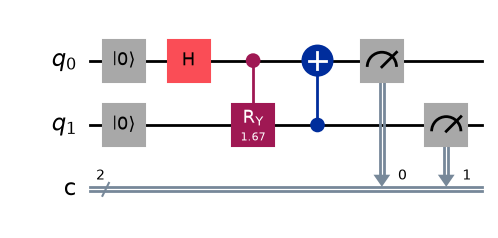

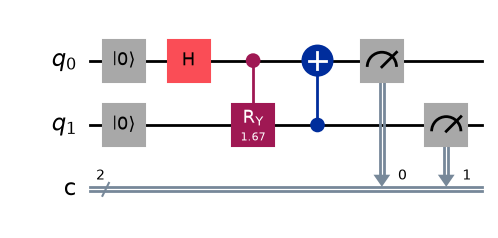

In [2]:
osq.build_amplitude_damping(rate, 1, "plus", observable="Z", reset=True).draw(output="mpl", fold=24)

## Independent reduced-density checks

For an input $\rho$, the reference is $K_0\rho K_0^\dagger+K_1\rho K_1^\dagger$, with $K_0=\operatorname{diag}(1,\sqrt{1-p})$ and $K_1=\sqrt p\,|0\rangle\langle1|$. Qiskit evolves the actual gate circuit and traces the environment. The finite-time reference retains exponential population/coherence survival directly, including when the scalar probability rounds to one. The table reports trace distance, positivity and measured X/Y/Z means for gate-prepared inputs.

In [3]:
records = [osq.compare_damping(rate, t, label) for label in input_labels for t in validation_times]
rows = [{"input": r["input"], "time": r["time"], "trace distance": r["trace_distance"],
         "minimum eigenvalue": r["minimum_eigenvalue"], "X": r["circuit_observables"]["X"],
         "Y": r["circuit_observables"]["Y"], "Z": r["circuit_observables"]["Z"]} for r in records]
assert max(r["trace_distance"] for r in records) < 1e-12
assert max(r["maximum_observable_error"] for r in records) < 1e-12
assert min(r["minimum_eigenvalue"] for r in records) > -1e-12
display(pd.DataFrame(rows).query("time in [0, 1, 2, 50]").reset_index(drop=True))

,input,time,trace distance,minimum eigenvalue,X,Y,Z
0,zero,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
1,zero,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
2,zero,2.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
3,zero,50.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
4,one,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000
5,one,1.0,2.775558e-17,4.493290e-01,0.000000e+00,0.000000e+00,0.101342
6,one,2.0,2.775558e-17,2.018965e-01,0.000000e+00,0.000000e+00,0.596207
7,one,50.0,1.877362e-25,4.248354e-18,0.000000e+00,0.000000e+00,1.000000
8,plus,0.0,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000
9,plus,1.0,6.938894e-17,6.624674e-02,6.703200e-01,0.000000e+00,0.550671


In [4]:
density = osq.simulate_prepared_damping(rate, 1, "plus")
display(pd.DataFrame(density, index=["0", "1"], columns=["0", "1"]))
print(f"Trace: {np.trace(density).real:.12f}; minimum eigenvalue: {np.linalg.eigvalsh(density).min():.12f}")

,0,1
0,0.775336+0.000000j,0.335160+0.000000j
1,0.335160+0.000000j,0.224664+0.000000j


Trace: 1.000000000000; minimum eigenvalue: 0.066246742411


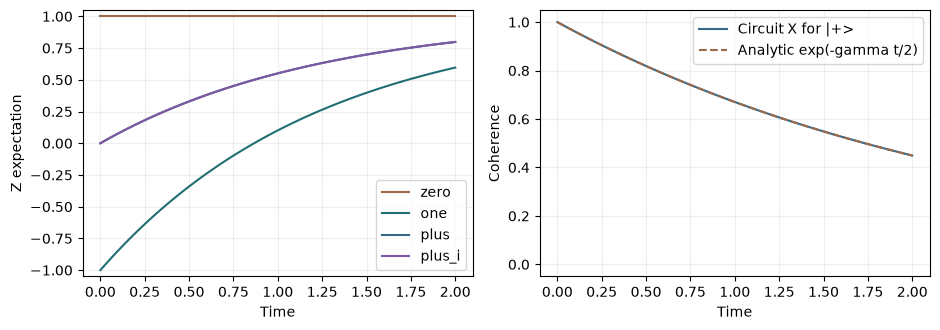

In [5]:
times = np.linspace(0, 2, 81)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for label, color in zip(input_labels, ("#9b694a", "#216e73", "#346b8a", "#8057a3")):
    values = [osq.compare_damping(rate, float(t), label) for t in times]
    axes[0].plot(times, [r["circuit_observables"]["Z"] for r in values], label=label, color=color)
plus = [osq.compare_damping(rate, float(t), "plus") for t in times]
axes[1].plot(times, [r["circuit_observables"]["X"] for r in plus], color="#346b8a", label="Circuit X for |+>")
axes[1].plot(times, np.exp(-rate*times/2), "--", color="#9b694a", label="Analytic exp(-gamma t/2)")
axes[0].set(xlabel="Time", ylabel="Z expectation", ylim=(-1.05, 1.05))
axes[1].set(xlabel="Time", ylabel="Coherence", ylim=(-.05, 1.05))
for ax in axes:
    ax.legend()
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

## Measured circuits and separate budgets

Each observable requires a fresh input and environment. X uses H before Z measurement; Y uses S-dagger then H; Z uses no basis rotation. Both qubits are measured and the environment bit is ignored. The resource table counts preparation, the decomposed access, resets and measurements. Its arbitrary rotations remain unsynthesized.

The proposed one-fixed-Z-mean budget uses 13,315 independent trials for sampling error 0.03 and statistical failure 0.005. This is not a joint X/Y/Z tomography or multi-time confidence guarantee. Coherent synthesis and physical faults have separate pending allowances.

In [6]:
counts = {}
for observable in ("X", "Y", "Z"):
    source = osq.build_amplitude_damping(rate, 1, "plus", observable=observable, reset=True)
    compiled = osq.lower_to_rotation_basis(source)
    counts[observable] = dict(compiled.count_ops())
display(pd.DataFrame(counts).fillna(0).astype(int))
shots = osq.observable_shots()
print(f"One fixed +/-1 observable proposal: {shots} independent trials")

,X,Y,Z
cx,3,3,3
reset,2,2,2
h,2,2,1
ry,2,2,2
measure,2,2,2
sdg,0,1,0


One fixed +/-1 observable proposal: 13315 independent trials


In [7]:
p_zero = float(density[0, 0].real)
zero_count = int(np.random.default_rng(41).binomial(shots, p_zero))
mean = 2*zero_count/shots-1
print(f"Seeded ideal-probability sampling: Z estimate {mean:.6f}; exact circuit mean {2*p_zero-1:.6f}")
print("This is one illustrative classical draw. The confidence bound is analytic, not certified by this draw.")

Seeded ideal-probability sampling: Z estimate 0.566955; exact circuit mean 0.550671
This is one illustrative classical draw. The confidence bound is analytic, not certified by this draw.


## Limits and input contract

The independent-channel generator supports up to 32 system wires and 32 separate environment wires, without allocating a density matrix. The public validation helpers stay at one system plus one environment. This tensor product is not an interacting many-body Lindblad algorithm. A caller-supplied quantum input uses no system reset; explicit resets are allowed only with named prepared inputs, so an unknown input is not erased.

A general Lindblad simulator, coherent synthesis, physical-resource projection, routing and measured hardware performance remain planned. Finite floating-angle precision near pi limits extreme-time accuracy. Classical coefficient/angle preparation and readout wall time are excluded from quantum gate counts and explicitly disclosed.